# Figures 7 and 11: derivative-free solvers

This notebook draws the figures of the derivative-free experiment (Section 3 and the appendix) of

> G. Fasano, C. Piermarini, M. Roma. *Benchmarking Optimization Algorithms with Quality Profiles.* Mathematical Programming Computation (accepted), [arXiv:2607.16798](https://arxiv.org/abs/2607.16798).

Each figure uses the same results and the same parameters `r1` and `r2` as the MATLAB script of the [reference repository](https://github.com/fasano-g/Quality-Profiles) that produced it, so the two implementations can be compared side by side. The MATLAB scripts all start with `r1 = 1; r2 = 1;` (line 186): to reproduce a figure with different values, set them there.

| Figure | Budget | Test set | `r1` | `r2` | MATLAB script |
| --- | --- | --- | --- | --- | --- |
| 7(a) | 1000·n | 145 problems | 1 | 1 | `Profiles_N_codes_v3_github_revised_Figure_7a.m` |
| 7(b) | 750·n | 145 problems | 1 | 1 | `Profiles_N_codes_v3_github_revised_Figure_7b.m` |
| 7(c) | 500·n | 145 problems | 1 | 1 | `Profiles_N_codes_v3_github_revised_Figure_7c.m` |
| 7(d) | 250·n | 145 problems | 1 | 1 | `Profiles_N_codes_v3_github_revised_Figure_7d.m` |
| 11(a) | 1000·n | 22 problems with n = 100 | 1 | 1 | `Profiles_N_codes_v3_github_revised_Figure_11a_n_100.m` |
| 11(b) | 750·n | 22 problems with n = 100 | 1 | 1 | `Profiles_N_codes_v3_github_revised_Figure_11b_n_100.m` |
| 11(c) | 500·n | 22 problems with n = 100 | 1 | 1 | `Profiles_N_codes_v3_github_revised_Figure_11c_n_100.m` |
| 11(d) | 250·n | 22 problems with n = 100 | 1 | 1 | `Profiles_N_codes_v3_github_revised_Figure_11d_n_100.m` |

The results are read from `examples/data` (see [`examples/data/README.md`](../examples/data/README.md)). The colors fade from red to blue as in the paper (`colors="paper"`).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt

from quality_profiles import plot_quality_profiles, quality_profiles

# The results of the paper are in examples/data; examples/utils/paper_data.py reads them.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "examples" / "data").is_dir())
sys.path.insert(0, str(ROOT / "examples"))
from utils.paper_data import load  # noqa: E402

plt.rcParams["figure.dpi"] = 110


def draw(figure, dataset, r1=1, r2=1, n=None, ax=None, legend=True, legend_loc="lower right"):
    """Compute and plot the quality profiles of one figure of the paper."""
    f0, f_solvers, names = load(dataset, n=n)
    qp = quality_profiles(f0, f_solvers, solver_names=names, r1=r1, r2=r2)
    title = f"{figure}: |S| = {len(names)}, |P| = {len(f0)}, r1 = {r1}, r2 = {r2}"
    plot_quality_profiles(qp, ax, colors="paper", title=title, legend=legend, legend_loc=legend_loc)
    return qp


def table(qp, levels=(1, 1e-1, 1e-3, 1e-6, 1e-9, 1e-12)):
    """Print the profiles at a few precision levels."""
    print(f"{'precision':>10s}" + "".join(f"{name:>14s}" for name in qp.solver_names))
    for level, row in zip(levels, qp.evaluate(levels), strict=True):
        print(f"{level:>10.0e}" + "".join(f"{value:>14.3f}" for value in row))

## Figure 7

Weak quality profiles of NEWUOA and six Direct Search methods (ALG1, ALG2, ALG4, ALG6, ALG7, ALG8) on 145 CUTEst problems, with a budget of (a) 1000·n, (b) 750·n, (c) 500·n and (d) 250·n function evaluations; `r1 = 1` and `r2 = 1`.

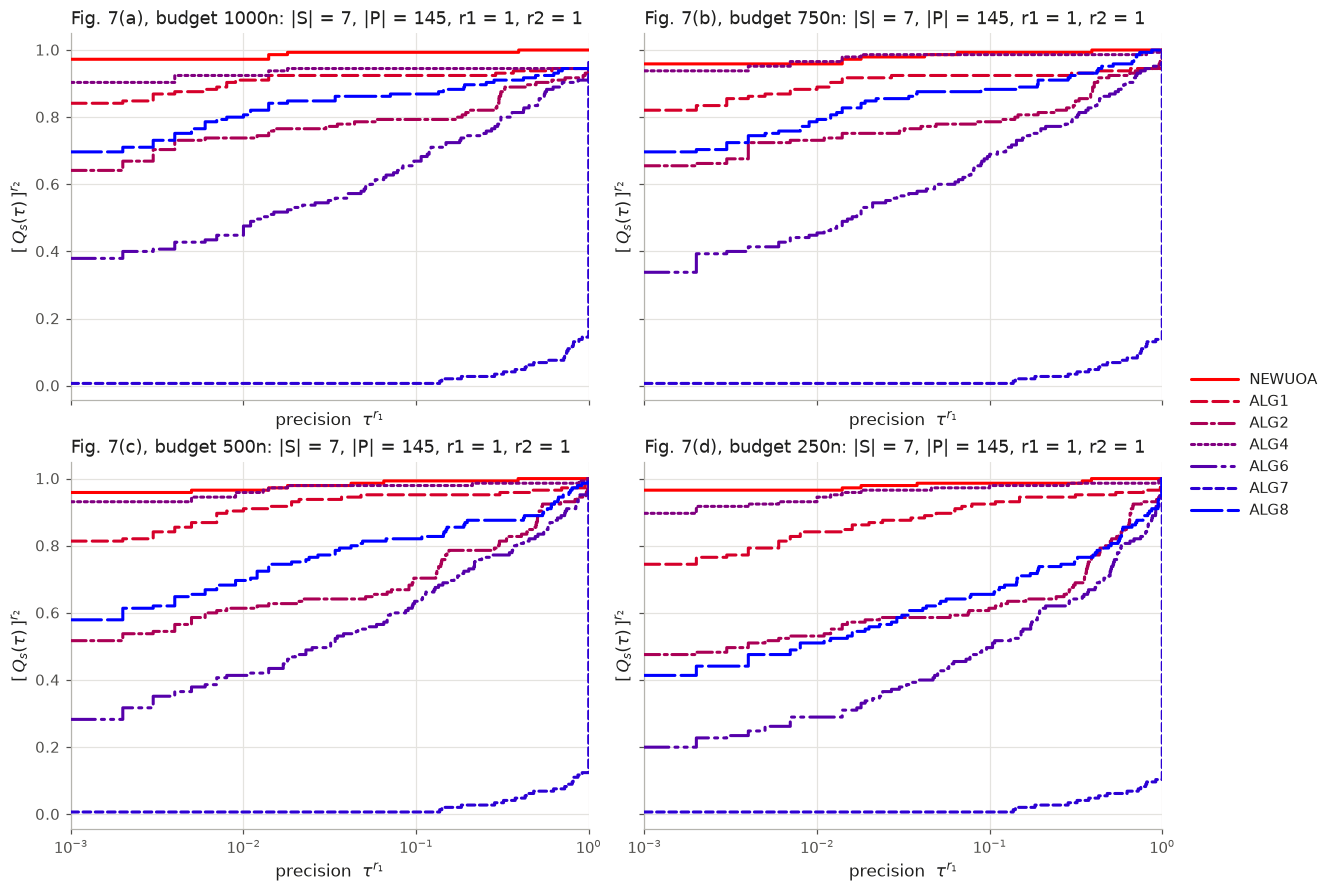

In [2]:
budgets = ["1000n", "750n", "500n", "250n"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8), layout="constrained", sharex=True, sharey=True)
for k, (ax, budget) in enumerate(zip(axes.flat, budgets, strict=True)):
    draw(
        f"Fig. 7({'abcd'[k]}), budget {budget}",
        f"dfo_budget_{budget}",
        r1=1,
        r2=1,
        n=None,
        ax=ax,
        legend=k == 0,
        legend_loc="outside right center",
    )
plt.show()

## Figure 11

As Figure 7, on the 22 problems with dimension $n = 100$ only.

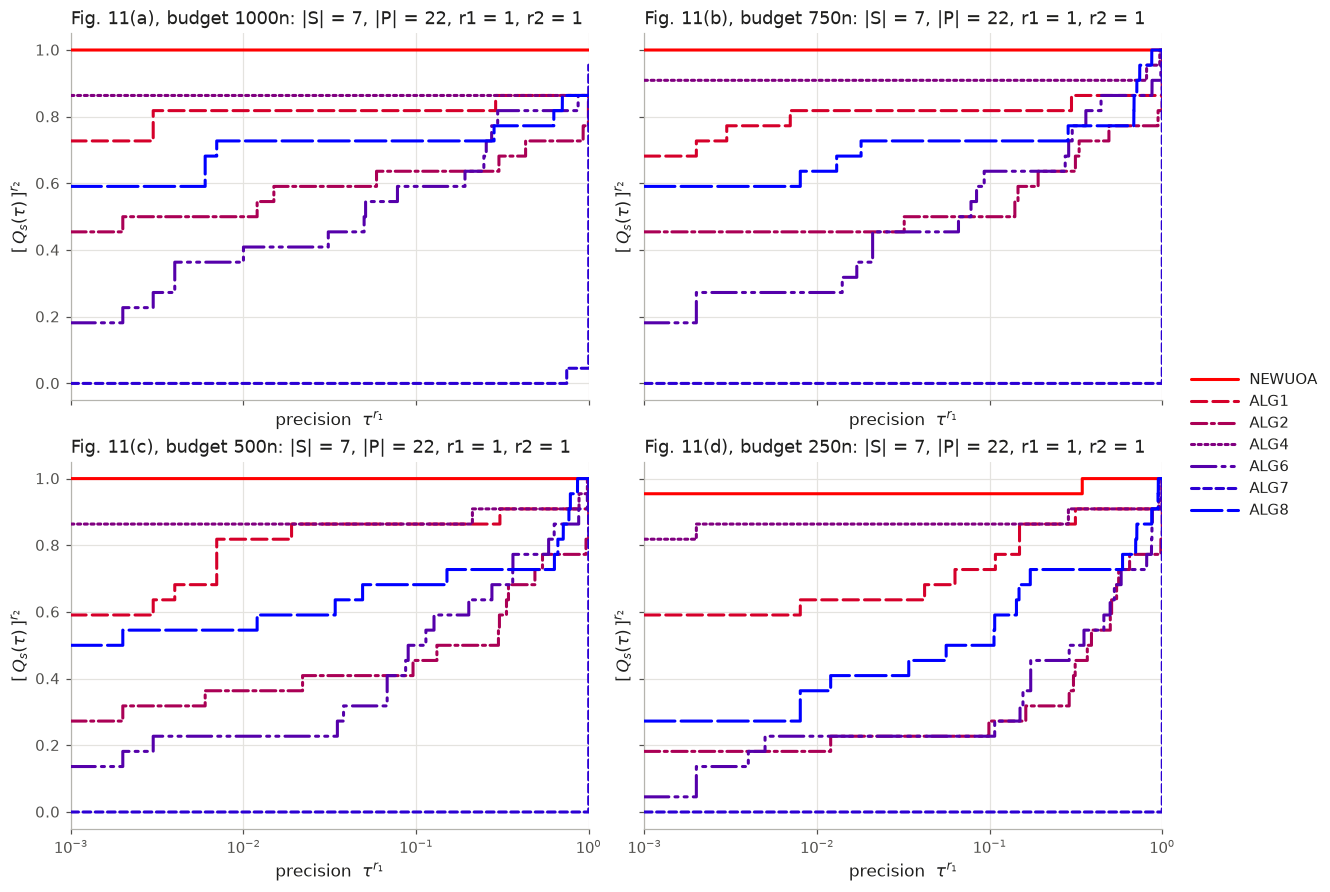

In [3]:
budgets = ["1000n", "750n", "500n", "250n"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8), layout="constrained", sharex=True, sharey=True)
for k, (ax, budget) in enumerate(zip(axes.flat, budgets, strict=True)):
    draw(
        f"Fig. 11({'abcd'[k]}), budget {budget}",
        f"dfo_budget_{budget}",
        r1=1,
        r2=1,
        n=100,
        ax=ax,
        legend=k == 0,
        legend_loc="outside right center",
    )
plt.show()

## Values at a few precision levels

Budget 1000·n, all 145 problems:

In [4]:
f0, f_solvers, names = load("dfo_budget_1000n")
table(quality_profiles(f0, f_solvers, solver_names=names), levels=(1, 1e-1, 1e-2, 1e-3))

 precision        NEWUOA          ALG1          ALG2          ALG4          ALG6          ALG7          ALG8
     1e+00         1.000         0.945         0.945         0.945         0.917         0.972         0.945
     1e-01         0.993         0.924         0.793         0.945         0.669         0.007         0.869
     1e-02         0.972         0.910         0.738         0.924         0.476         0.007         0.807
     1e-03         0.972         0.841         0.641         0.903         0.379         0.007         0.697
